# Data Cleaning - IEEE Fraud Detection

### Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

### Load the data

In [2]:
train_transaction = pd.read_csv("train_transaction.csv")
train_identity = pd.read_csv("train_identity.csv")

test_transaction = pd.read_csv("test_transaction.csv")
test_identity = pd.read_csv("test_identity.csv")

In [3]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


### Merge both tables

In [5]:
train = train_transaction.merge(train_identity, on='TransactionID', how='left')
test = test_transaction.merge(test_identity, on='TransactionID', how='left')

print("Train shape:", train.shape)
print("Test shape:", test.shape)

del train_transaction, train_identity, test_transaction, test_identity

Train shape: (590540, 434)
Test shape: (506691, 433)


In [6]:
train.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


### Class imbalance check

In [7]:
train['isFraud'].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

### Graph 1: Fraud vs Non-Fraud transaction count

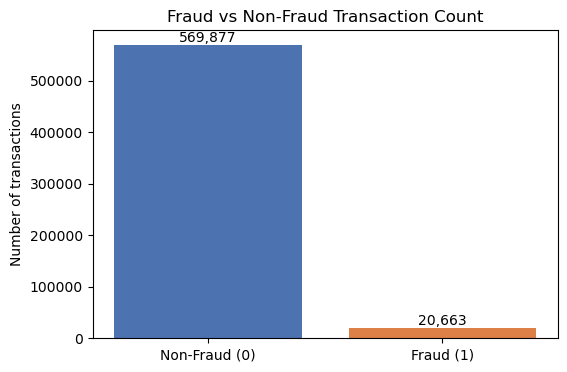

In [8]:
fraud_counts = train['isFraud'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(['Non-Fraud (0)', 'Fraud (1)'], fraud_counts.values, color=['#4C72B0', '#DD8047'])
plt.title('Fraud vs Non-Fraud Transaction Count')
plt.ylabel('Number of transactions')

for i, value in enumerate(fraud_counts.values):
    plt.text(i, value, f'{value:,}', ha='center', va='bottom')

plt.show()

### Check missing values

In [9]:
missing = train.isnull().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print("Columns with missing values:", len(missing))
missing.head(20)

Columns with missing values: 414


id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
dtype: float64

### Graph 2: Top 15 columns with most missing values

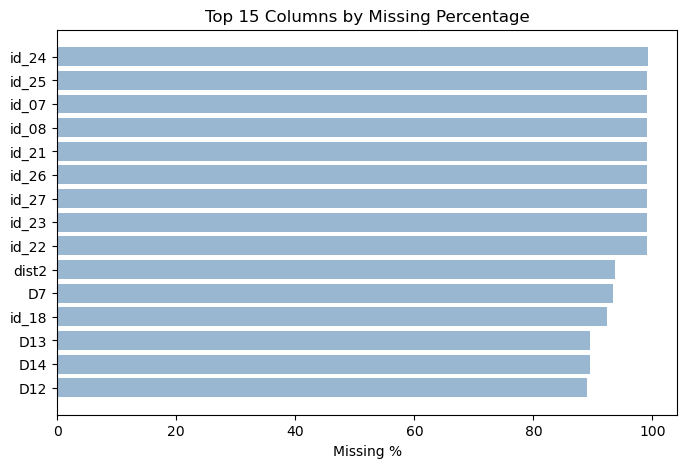

In [10]:
top_missing = missing.head(15)

plt.figure(figsize=(8, 5))
plt.barh(top_missing.index[::-1], top_missing.values[::-1], color='#99B7D1')
plt.xlabel('Missing %')
plt.title('Top 15 Columns by Missing Percentage')
plt.show()

### Missing indicator columns

In [11]:
cols_for_indicator = missing[missing > 30].index.tolist()

for col in cols_for_indicator:
    train[col + '_isnull'] = train[col].isnull()
    train[col + '_isnull'] = train[col + '_isnull'].astype(int)

    if col in test.columns:
        test[col + '_isnull'] = test[col].isnull()
        test[col + '_isnull'] = test[col + '_isnull'].astype(int)

print("Indicator columns created:", len(cols_for_indicator))

Indicator columns created: 232


### Drop columns with more than 90% missing values

In [12]:
cols_to_drop = missing[missing > 90].index.tolist()
print("Dropping", len(cols_to_drop), "columns")

train = train.drop(columns=cols_to_drop)

for col in cols_to_drop:
    if col in test.columns:
        test = test.drop(columns=[col])

print("Train shape:", train.shape)

Dropping 12 columns
Train shape: (590540, 654)


### Get hour and day from TransactionDT

In [13]:
train['TransactionHour'] = (train['TransactionDT'] // 3600) % 24
train['TransactionDay'] = (train['TransactionDT'] // (3600 * 24)) % 7

test['TransactionHour'] = (test['TransactionDT'] // 3600) % 24
test['TransactionDay'] = (test['TransactionDT'] // (3600 * 24)) % 7

train[['TransactionDT', 'TransactionHour', 'TransactionDay']].head()

,TransactionDT,TransactionHour,TransactionDay
0,86400,0,1
1,86401,0,1
2,86469,0,1
3,86499,0,1
4,86506,0,1


### Graph 4: Fraud rate by hour of day

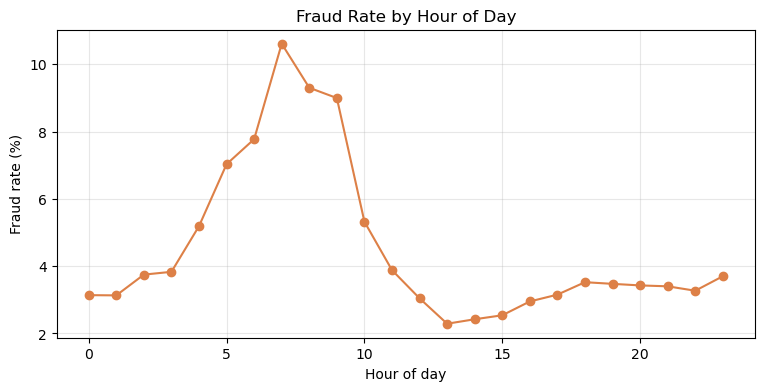

In [14]:
fraud_by_hour = train.groupby('TransactionHour')['isFraud'].mean() * 100

plt.figure(figsize=(9, 4))
plt.plot(fraud_by_hour.index, fraud_by_hour.values, marker='o', color='#DD8047')
plt.xlabel('Hour of day')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate by Hour of Day')
plt.grid(True, alpha=0.3)
plt.show()

### Simplify email domains

In [15]:
def group_email(domain):
    if pd.isna(domain):
        return domain
    domain = str(domain)
    if 'gmail' in domain:
        return 'google'
    elif 'yahoo' in domain:
        return 'yahoo'
    elif 'hotmail' in domain or 'outlook' in domain or 'live.com' in domain:
        return 'microsoft'
    elif 'icloud' in domain or 'mac.com' in domain:
        return 'apple'
    else:
        return 'other'

train['P_emaildomain'] = train['P_emaildomain'].apply(group_email)
test['P_emaildomain'] = test['P_emaildomain'].apply(group_email)

train['R_emaildomain'] = train['R_emaildomain'].apply(group_email)
test['R_emaildomain'] = test['R_emaildomain'].apply(group_email)

train['P_emaildomain'].value_counts()

P_emaildomain
google       228851
yahoo        102909
other        102292
microsoft     55329
apple          6703
Name: count, dtype: int64

### Separate categorical and numeric columns

In [16]:
cat_cols = train.select_dtypes(include='object').columns.tolist()
num_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()

num_cols.remove('isFraud')
num_cols.remove('TransactionID')

print("Categorical columns:", len(cat_cols))
print("Numeric columns:", len(num_cols))

Categorical columns: 29
Numeric columns: 625


### Fill missing values

In [17]:
for col in num_cols:
    median_value = train[col].median()
    train[col] = train[col].fillna(median_value)
    if col in test.columns:
        test[col] = test[col].fillna(median_value)

for col in cat_cols:
    train[col] = train[col].fillna('missing')
    if col in test.columns:
        test[col] = test[col].fillna('missing')

print("NaNs left in train:", train.isnull().sum().sum())

NaNs left in train: 0


### Drop TransactionID

In [18]:
train = train.drop(columns=['TransactionID'])
test = test.drop(columns=['TransactionID'])

print("Train shape:", train.shape)

Train shape: (590540, 655)


### Remove columns with only 1 unique value

In [19]:
cols_to_remove = []

for col in train.columns:
    if col == 'isFraud':
        continue
    if train[col].nunique() <= 1:
        cols_to_remove.append(col)

print("Removing", len(cols_to_remove), "columns")

train = train.drop(columns=cols_to_remove)

for col in cols_to_remove:
    if col in test.columns:
        test = test.drop(columns=[col])

Removing 0 columns


### Graph 3: Correlation heatmap (sample of columns)

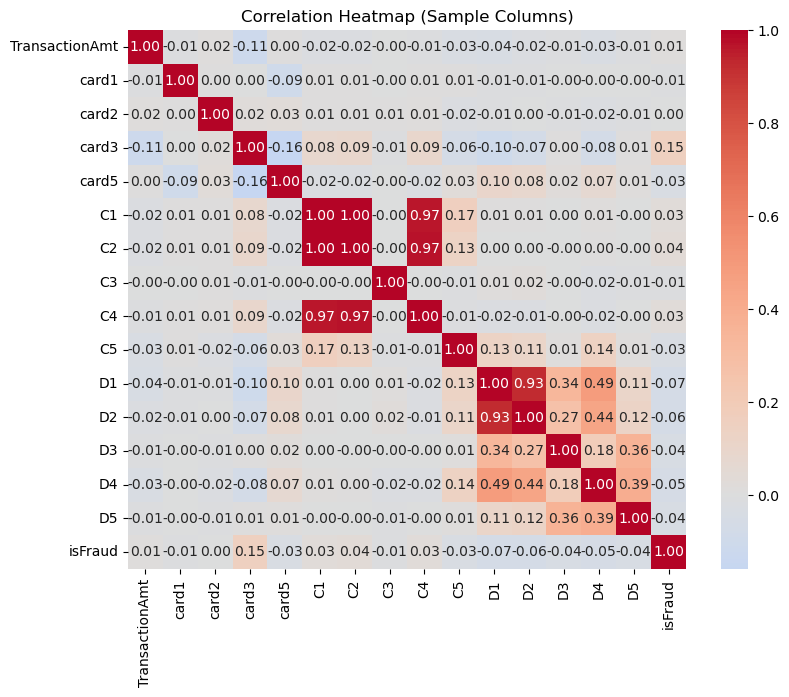

In [20]:
sample_cols = ['TransactionAmt', 'card1', 'card2', 'card3', 'card5',
               'C1', 'C2', 'C3', 'C4', 'C5',
               'D1', 'D2', 'D3', 'D4', 'D5', 'isFraud']
sample_cols = [c for c in sample_cols if c in train.columns]

plt.figure(figsize=(9, 7))
sns.heatmap(train[sample_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Sample Columns)')
plt.show()

### Remove highly correlated columns

In [21]:
num_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols.remove('isFraud')

corr_matrix = train[num_cols].corr()

columns_to_drop = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        value = corr_matrix.iloc[i, j]
        if abs(value) > 0.95:
            col_name = corr_matrix.columns[i]
            if col_name not in columns_to_drop:
                columns_to_drop.append(col_name)

print("Removing", len(columns_to_drop), "correlated columns")

train = train.drop(columns=columns_to_drop)

for col in columns_to_drop:
    if col in test.columns:
        test = test.drop(columns=[col])

Removing 317 correlated columns


In [22]:
rename_map = {c: c.replace('-', '_') for c in test.columns if c.startswith('id-')}
print("Renaming", len(rename_map), "columns in test")
test = test.rename(columns=rename_map)

Renaming 38 columns in test


### Label Encoding

In [23]:
from sklearn.preprocessing import LabelEncoder

cat_cols = train.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    le = LabelEncoder()
    combined_values = list(train[col].astype(str)) + list(test[col].astype(str))
    le.fit(combined_values)

    train[col] = le.transform(train[col].astype(str))
    test[col] = le.transform(test[col].astype(str))

print("Encoded", len(cat_cols), "columns")
train[cat_cols].head()

Encoded 29 columns


,ProductCD,card4,card6,P_emaildomain,R_emaildomain,M1,M2,M3,M4,M5,...,id_30,id_31,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,4,1,1,3,3,1,1,1,2,0,...,86,128,461,4,2,2,2,2,1,2703
1,4,2,1,1,3,2,2,2,0,1,...,86,128,461,4,2,2,2,2,1,2703
2,4,4,2,2,3,1,1,1,0,0,...,86,128,461,4,2,2,2,2,1,2703
3,4,2,2,5,3,2,2,2,0,1,...,86,128,461,4,2,2,2,2,1,2703
4,1,2,1,1,3,2,2,2,3,2,...,7,163,268,3,1,0,1,1,2,1565


### Final check

In [24]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("NaNs in train:", train.isnull().sum().sum())
train.head()

Train shape: (590540, 338)
Test shape: (506691, 339)
NaNs in train: 0


,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,dist1_isnull,M5_isnull,M7_isnull,D5_isnull,M4_isnull,D2_isnull,V11_isnull,D3_isnull,TransactionHour,TransactionDay
0,0,86400,68.5,4,13926,361.0,150.0,1,142.0,1,...,0,0,1,1,0,1,0,0,0,1
1,0,86401,29.0,4,2755,404.0,150.0,2,102.0,1,...,1,0,1,1,0,1,1,1,0,1
2,0,86469,59.0,4,4663,490.0,150.0,4,166.0,2,...,0,0,0,1,0,1,0,1,0,1
3,0,86499,50.0,4,18132,567.0,150.0,2,117.0,2,...,1,0,1,0,0,0,1,0,0,1
4,0,86506,50.0,1,4497,514.0,150.0,2,102.0,1,...,1,1,1,1,1,1,1,1,0,1


### Save cleaned data

In [25]:
train.to_csv('train_cleaned.csv', index=False)
test.to_csv('test_cleaned.csv', index=False)

print("Saved!")

Saved!
